# Supplementary Fig. S7: Per-monkey decoding performance of feedback, target and value

[AI generated summary] Same decoders and plotting function as Fig. 3f (`fig3f_population_decoding.ipynb`), shown over longer time windows: (a) feedback and (b) chosen target of trial t, decoded from the population activity over trial t and the next trial t+1 (logistic regression); (c) foraging value of trial t, decoded within trial t (regression decoder). The curves show the percentage of sessions with significant decoding (permutation test, p < 0.05 in at least 4 consecutive 50-ms bins) in MCC, dLPFC and vLPFC, for each monkey. Panel c uses an earlier value-decoding run than Fig. 3f (June 2025, decoding window: trial t only, earlier version of the decoder code); it is the run used for this figure in the paper, so re-running `stay_value_current_trial` with the current code gives slightly different values (e.g. peak of KA vLPFC 53% instead of 60%).

**How to run:** set `DATA_PATH` in `popy/config.py` (uses `behavior/recordings_summary.csv`), then run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/population_decoding/fb_target and results/population_decoding/stay_value_current_trial` (see the README). To recompute them, run in this folder: `python run_decoding.py fb_target` (a, b; several hours on a server) and `python run_decoding.py stay_value_current_trial` (c; about 3 hours on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% imports
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

from popy.plotting.plotting_tools import plot_keypoints
from popy.config import COLORS

from helpers_decoding import load_decoding_res_new, mask_N_consecutives, add_subareas

# set fontsize to 8
plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_simple_decoding_signif_only(
    res,
    t_window=None,
    mark_event=None,
    n_extra_trials=(0, 1),
    ylim=None,
    title=None,
    ax=None,
):
    """
    Plot only the first panel from plot_simple_decoding:
    percent significant sessions over time for MCC, dLPFC, and vLPFC.
    """
    from scipy.ndimage import uniform_filter

    axis_original = ax

    if ax is None:
        plt.rcParams.update({'font.size': 8})
        fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.0))

    for subregion in ['MCC', 'dLPFC', 'vLPFC']:
        res_temp = (
            res.sel(area='MCC')
            if subregion == 'MCC'
            else res.sel(area='LPFC', session=res.lpfc_subregion == subregion)
        )

        signif_data_in_time = res_temp.if_significant.mean(dim='session')
        signif_data_in_time_smooth = uniform_filter(
            signif_data_in_time, size=5, mode='constant', cval=0.0
        )
        signif_data_in_time_smooth = signif_data_in_time_smooth * 100

        ax.plot(
            res_temp.time,
            signif_data_in_time_smooth,
            color=COLORS[subregion],
            label=subregion,
            lw=1.2,
        )

    plot_keypoints(
        ax,
        n_extra_trials=n_extra_trials,
        fontsize=8,
        rotation=0,
        mark_event=mark_event,
        xlabels='short',
    )
    ax.grid(axis='x', alpha=0.5, linestyle='--')

    # set y ticks 0 .25, .5, .75, 100
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_yticklabels(['0', '25', '50', '75', '100'])

    if title is not None:
        ax.set_title(title, fontsize=8)
    if ylim is not None:
        ax.set_ylim(ylim)

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Percent signif.\nsessions (%)')

    if t_window is not None:
        ax.set_xlim(t_window)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    #plt.tight_layout()

    if axis_original is None:
        return fig, ax
    return ax

---
# Supplementary Fig. S7a-c: Decoding feedback and target (trial t and t+1) and value (trial t)

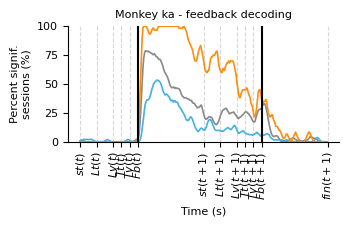

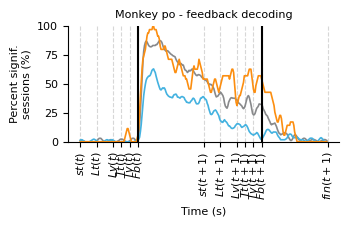

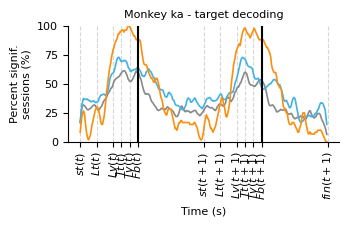

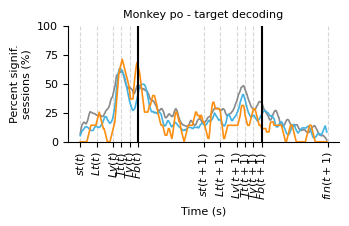

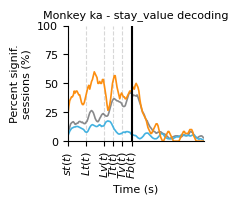

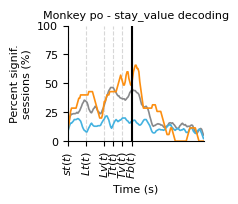

In [4]:
# for each monkey and each target variable (fb, value, target), we plot the 3 areas

plim = .05
n_extra_trials = (0, 1)
N_consecutives = 4

paper_format=False

configs = {
    'feedback': {
        'target': 'feedback',
        'folder': 'fb_target',
        't_window': None,  # whole window: trial t and t+1
        'figsize': (3.5, 1.5),
    },
    'target': {
        'target': 'target',
        'folder': 'fb_target',
        't_window': None,  # whole window: trial t and t+1
        'figsize': (3.5, 1.5),
    },
    'stay_value': {
        'target': 'stay_value',
        'folder': 'stay_value_current_trial',  # decoding within trial t only
        't_window': [0, 7.45],
        'figsize': (1.75, 1.5),
    }
}

for config_name, config in configs.items():
    target = config['target']
    folder = config['folder']
    t_window = config['t_window']

    # load results

    res = load_decoding_res_new(folder=folder)
    res = add_subareas(res)  # add subareas to the results 
    res = res.sel(target=target)  # select target of interest, e.g. feedback or value

    # if 'group' in dims and its nan, remove it. if not nan, raise error
    if 'group_target' in res.dims:
        if res.group_target == 'None':
            res = res.mean('group_target')
        else:
            raise ValueError("group_target was used so the plotting method cant handle this.")
        
    # mask significants
    res_target_signifs = mask_N_consecutives(res.pvals <= plim, N=N_consecutives)  # mask N consecutive non-significant bins
    res['if_significant'] = res_target_signifs  # add as new dataarray to the results

    for monkey in np.unique(res.monkey.values):
        res_temp = res.sel(session=res.monkey == monkey)
        title = f'Monkey {monkey} - {target} decoding'
        fig, axs = plt.subplots(1, 1, figsize=config['figsize'])
        plot_simple_decoding_signif_only(res_temp, t_window=t_window, mark_event='Fb', n_extra_trials=n_extra_trials, title=title, ylim=(0, 100), ax=axs)
        plot_keypoints(axs, n_extra_trials=n_extra_trials, fontsize=8, rotation=90, xlabels='events')  # label the events of trial t and t+1
        if t_window is not None:
            axs.set_xlim(t_window)  # (plot_keypoints extends the x axis to all event ticks)
        # save the figure
        floc = os.path.join(FIGS_PATH, f'figS7_{monkey}_{target}_decoding.svg')
        plt.savefig(floc, bbox_inches='tight', dpi=300, transparent=True)
        plt.show()
        plt.close()

In [5]:
# Export source data (Supplementary Figure 7a-c)
from popy.source_data import export_source_data
import pandas as pd
from scipy.ndimage import uniform_filter

# curves as computed in plot_simple_decoding_signif_only (same results, masking and smoothing as above), within the plotted windows
sd_panels = {'feedback': 'Supplementary Figure 7a', 'target': 'Supplementary Figure 7b', 'stay_value': 'Supplementary Figure 7c'}
sd_titles = {'feedback': 'Feedback decoding', 'target': 'Target decoding', 'stay_value': 'Value decoding'}
sd_descr = {
    'feedback': 'of the feedback of trial t (logistic regression, 5-fold cross-validation), decoded over trial t and t+1',
    'target': 'of the chosen target of trial t (logistic regression, 5-fold cross-validation), decoded over trial t and t+1',
    'stay_value': 'of the foraging value of trial t (regression decoder, 10-fold cross-validation), decoded within trial t',
}
sd_time_col = 'Time in the normalized trial (s)'
sd_check = {}
for config_name, config in configs.items():
    sd_tables, sd_n_sessions = {}, []
    sd_res = load_decoding_res_new(folder=config['folder'])
    sd_res = add_subareas(sd_res)
    sd_res = sd_res.sel(target=config['target'])
    if 'group_target' in sd_res.dims:
        if sd_res.group_target == 'None':
            sd_res = sd_res.mean('group_target')
        else:
            raise ValueError("group_target was used so the plotting method cant handle this.")
    sd_res['if_significant'] = mask_N_consecutives(sd_res.pvals <= plim, N=N_consecutives)

    for sd_monkey in np.unique(sd_res.monkey.values):
        sd_res_monkey = sd_res.sel(session=sd_res.monkey == sd_monkey)
        sd_df = pd.DataFrame({sd_time_col: np.round(sd_res_monkey.time.values, 3)})
        for subregion in ['MCC', 'dLPFC', 'vLPFC']:
            sd_res_area = (sd_res_monkey.sel(area='MCC') if subregion == 'MCC'
                           else sd_res_monkey.sel(area='LPFC', session=sd_res_monkey.lpfc_subregion == subregion))
            sd_curve = uniform_filter(sd_res_area.if_significant.mean(dim='session'), size=5, mode='constant', cval=0.0) * 100
            sd_df[f'{subregion}, significant sessions (%)'] = np.round(sd_curve, 10)  # (rounding removes float noise)
            sd_n_sessions.append({'Monkey': sd_monkey.upper(), 'Region': subregion,
                                  'Number of sessions (n)': sd_res_area.sizes['session'],
                                  'of which without decoding results (counted as non-significant)':
                                      int(sd_res_area.pvals.isnull().all('time').sum())})
        sd_window = config['t_window'] if config['t_window'] is not None else [sd_df[sd_time_col].min(), sd_df[sd_time_col].max()]
        sd_visible = (sd_df[sd_time_col] >= sd_window[0] - 1e-6) & (sd_df[sd_time_col] <= sd_window[1] + 1e-6)
        sd_tables[f'{sd_titles[config_name]}, monkey {sd_monkey.upper()}'] = sd_df[sd_visible].reset_index(drop=True)
        sd_check[(config_name, sd_monkey)] = (sd_res_monkey, config['t_window'], sd_tables[f'{sd_titles[config_name]}, monkey {sd_monkey.upper()}'])
    sd_tables['Number of sessions'] = pd.DataFrame(sd_n_sessions)

    export_source_data(
        sd_panels[config_name], sd_tables,
        f'Percentage of sessions with significant decoding (permutation test, p < 0.05 in at least 4 consecutive 50-ms bins) '
        f'{sd_descr[config_name]}, in MCC, dLPFC and vLPFC, for each monkey, as a function of time in the normalized trial '
        f'(s; trial t from 0 to 7.5 s, trial t+1 from 7.5 to 15 s; time markers within each trial: Lt = 1 s, Tt = 2.5 s, '
        f'Fb = 3.5 s), within the plotted window. Curves are smoothed with a 5-bin moving average; the exported values are '
        f'the smoothed values drawn. n = number of sessions per curve (last table).'
    )

Supplementary Figure 7a: source data saved (300 rows, 300 rows, 6 rows)
Supplementary Figure 7b: source data saved (300 rows, 300 rows, 6 rows)
Supplementary Figure 7c: source data saved (150 rows, 150 rows, 6 rows)
